# Physics-Informed Battery Stress Index

A companion to `01_driving_behaviour_stress_analysis.ipynb`. That notebook's Battery Stress Index is a hand-weighted composite (35% thermal + 30% C-rate + 20% depth-of-discharge + 15% SoC-extreme, each min-max normalized) &mdash; declared, not fit. The cross-dataset validation work (`nasa_vs_tum_comparison.py`, `calce_crate_test.py`) found the weakest part of that assumption is exactly the thermal/C-rate portion: on NASA's real aging data, the direction of the temperature&ndash;C-rate relationship flips relative to TUM.

This notebook replaces **only the thermal + C-rate 65% of the index** with a semi-empirical Li-ion capacity-fade model (Arrhenius temperature term &times; C-rate power-law &times; Ah-throughput power-law &mdash; the standard form in the aging literature) whose constants are *fit*, not guessed, using the real measured capacity fade in NASA (temperature variation, near-constant C-rate) and CALCE (two controlled C-rates, no temperature variation) together. The remaining 35% (depth-of-discharge 20% + SoC-extreme 15%) stays exactly as before, because neither NASA nor CALCE cycles at varied depth of discharge &mdash; there's no ground truth here to calibrate that part against.

Section 6 goes one step further: it doesn't touch the functional *form* of thermal/C-rate/throughput fade, but it does data-calibrate their *relative weight* against each other (and, by extension, against depth-of-discharge) using the same fitted regression. SoC-extreme exposure remains the one weight nothing in this project can calibrate from data.

The new label is then plugged into the same modeling pipeline as the original notebook (same features, same grouped cross-validation, same XGBoost configuration) so the two are a fair comparison.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb
import shap

warnings.filterwarnings("ignore")
if sys.stdout.encoding is not None and sys.stdout.encoding.lower() != "utf-8":
    sys.stdout.reconfigure(encoding="utf-8")

OUT_FIG_DIR = os.path.join("outputs", "figures")
OUT_DATA_DIR = os.path.join("outputs", "data")
OUT_MODEL_DIR = os.path.join("outputs", "model")
for d in (OUT_FIG_DIR, OUT_DATA_DIR, OUT_MODEL_DIR):
    os.makedirs(d, exist_ok=True)

NOMINAL_CAPACITY_AH = 60.0   # BMW i3 (60 Ah) pack -- same assumption as the main notebook
WINDOW_S = 60                # sliding-window length, seconds -- same as the main notebook
R_GAS = 8.314                # J / (mol . K)
RANDOM_STATE = 42

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
sns.set_theme(style="whitegrid", rc={
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.family": "sans-serif",
})
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=PALETTE)
pd.set_option("display.max_columns", 60)

def minmax(s):
    lo, hi = s.min(), s.max()
    if hi - lo < 1e-9:
        return pd.Series(0.0, index=s.index)
    return (s - lo) / (hi - lo)

C:\Users\ritha\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Section 1 &mdash; Calibration data: NASA (temperature) + CALCE (C-rate)

Reuses the already-parsed per-cycle tables from `nasa_vs_tum_comparison.py` and `calce_crate_test.py`. Neither dataset alone can identify a temperature-*and*-C-rate model:

- NASA's four cells are all cycled at ~0.9C (a narrow C-rate range) but real cell temperature during discharge varies ~36&ndash;42&deg;C from self-heating, at a fixed ~24&deg;C ambient.
- CALCE's four cells are held at room temperature (not logged &mdash; no within-dataset variation) but are deliberately split 0.5C vs. 1C.

Pooling them lets NASA identify the temperature term and CALCE identify the C-rate term. A dataset dummy absorbs the baseline difference between chemistries/formats (NASA 18650 cells vs. CALCE pouch cells), so the two datasets only need to agree on how fade *scales* with temperature and C-rate, not on its absolute rate &mdash; which is exactly the part needed for a per-window multiplier.

In [2]:
nasa = pd.read_csv(os.path.join(OUT_DATA_DIR, "nasa_battery_discharge_cycles.csv"))
calce = pd.read_csv(os.path.join(OUT_DATA_DIR, "calce_cs2_discharge_cycles.csv"))

# NASA: already trimmed to capacity >= 65% of rated in the saved CSV.
nasa = nasa.sort_values(["battery_id", "discharge_cycle_idx"]).copy()
nasa["ah_cum"] = nasa.groupby("battery_id")["capacity_ah"].cumsum()
nasa_cal = pd.DataFrame({
    "dataset": "NASA", "cell_id": nasa["battery_id"],
    "ah_cum": nasa["ah_cum"],
    "q_loss_pct": (100 - nasa["capacity_pct_of_rated"]).clip(lower=0.5),
    "c_rate": nasa["c_rate_nominal"],       # vs. rated capacity -- same convention TUM uses
    "temp_c": nasa["temp_max_c"],           # measured cell temperature, not ambient
})

# CALCE: same shared early/clean cycle window used in calce_crate_test.py (before any
# individual cell's end-of-life knee).
calce = calce.sort_values(["cell_id", "global_cycle_idx"]).copy()
calce = calce[calce["global_cycle_idx"] <= 60].copy()
calce["ah_cum"] = calce.groupby("cell_id")["capacity_ah"].cumsum()
calce_cal = pd.DataFrame({
    "dataset": "CALCE", "cell_id": calce["cell_id"],
    "ah_cum": calce["ah_cum"],
    "q_loss_pct": (100 - calce["capacity_pct_of_rated"]).clip(lower=0.5),
    "c_rate": calce["c_rate_nominal_rated"],
    "temp_c": 24.0,   # not logged; CALCE's own design holds ambient ~constant across all 4 cells
})

cal_df = pd.concat([nasa_cal, calce_cal], ignore_index=True)
cal_df["temp_k"] = cal_df["temp_c"] + 273.15
print(f"Calibration sample: {len(cal_df)} cycles -- "
      f"{(cal_df.dataset=='NASA').sum()} NASA, {(cal_df.dataset=='CALCE').sum()} CALCE -- "
      f"across {cal_df.cell_id.nunique()} cells")
cal_df.groupby("dataset")[["temp_c", "c_rate", "q_loss_pct"]].describe().T

Calibration sample: 842 cycles -- 602 NASA, 240 CALCE -- across 8 cells


dataset                CALCE        NASA
temp_c     count  240.000000  602.000000
           mean    24.000000   39.492488
           std      0.000000    1.435828
           min     24.000000   36.372088
           25%     24.000000   38.276082
           50%     24.000000   39.482807
           75%     24.000000   40.825102
           max     24.000000   42.332522
c_rate     count  240.000000  602.000000
           mean     0.750000    0.923654
           std      0.250522    0.044036
           min      0.500000    0.824678
           25%      0.500000    0.892535
           50%      0.750000    0.928931
           75%      1.000000    0.957377
           max      1.000000    0.999878
q_loss_pct count  240.000000  602.000000
           mean     1.285063   19.959518
           std      1.873349    9.257119
           min      0.500000    0.500000
           25%      0.500000   11.371123
           50%      0.500000   20.923784
           75%      1.024943   28.082050
           max     12.566318   34.988213

## Section 2 &mdash; Fit the semi-empirical fade model

Standard Wang-et-al.-style capacity-fade form:

**Q_loss(%) = B &middot; exp(&minus;Ea / R&middot;T) &middot; C<sup>m</sup> &middot; Ah<sup>z</sup>**

Log-linearized: `ln(Q_loss) = ln(B) - (Ea/R)*(1/T) + m*ln(C) + z*ln(Ah)`. Fit by pooled OLS with an `is_NASA` dummy for the intercept (a separate baseline `B` per dataset/chemistry) and cluster-robust standard errors by cell &mdash; 4 cells total across both datasets, so this is a small, transparent fit, not a high-powered one.

In [3]:
cal_df["y"] = np.log(cal_df["q_loss_pct"])
cal_df["inv_T"] = 1.0 / cal_df["temp_k"]
cal_df["ln_C"] = np.log(cal_df["c_rate"])
cal_df["ln_Ah"] = np.log(cal_df["ah_cum"].clip(lower=1e-6))
cal_df["is_NASA"] = (cal_df["dataset"] == "NASA").astype(int)

X_cal = sm.add_constant(cal_df[["inv_T", "ln_C", "ln_Ah", "is_NASA"]])
fade_model = sm.OLS(cal_df["y"], X_cal).fit(cov_type="cluster", cov_kwds={"groups": cal_df["cell_id"]})
print(fade_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     333.2
Date:                Fri, 11 Sep 2026   Prob (F-statistic):           4.62e-08
Time:                        23:18:14   Log-Likelihood:                -655.71
No. Observations:                 842   AIC:                             1321.
Df Residuals:                     837   BIC:                             1345.
Df Model:                           4                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.5092     28.834      0.330      0.7

Activation energy  Ea =   27.8 kJ/mol   (p=0.6968, 95% CI [-112, 167])  [literature range for Li-ion cathode aging: roughly 20-90 kJ/mol]
C-rate exponent     m = +0.799         (p=0.0402)
Throughput exponent z = +0.544         (p=0.0000)
R-squared = 0.886

C-rate (m) and throughput (z) are both statistically significant at alpha=0.05 -- m is pinned down mainly by CALCE's controlled 0.5C-vs-1C contrast, z by both datasets' within-cell fade-vs-cycle-count trend, and z's value (0.54) lands close to the ~0.5 exponent commonly reported for early-life power-law fade in the literature.
Ea, by contrast, is NOT statistically significant (p=0.70) -- its point estimate happens to fall in a physically plausible range, but the 95% CI [-112, 167] kJ/mol spans from unphysical to implausibly high. NASA's within-cell temperature spread (~6 degC of self-heating, at one fixed ambient) is too narrow to pin down an Arrhenius slope precisely, and CALCE contributes no temperature variation at all. Treat the 

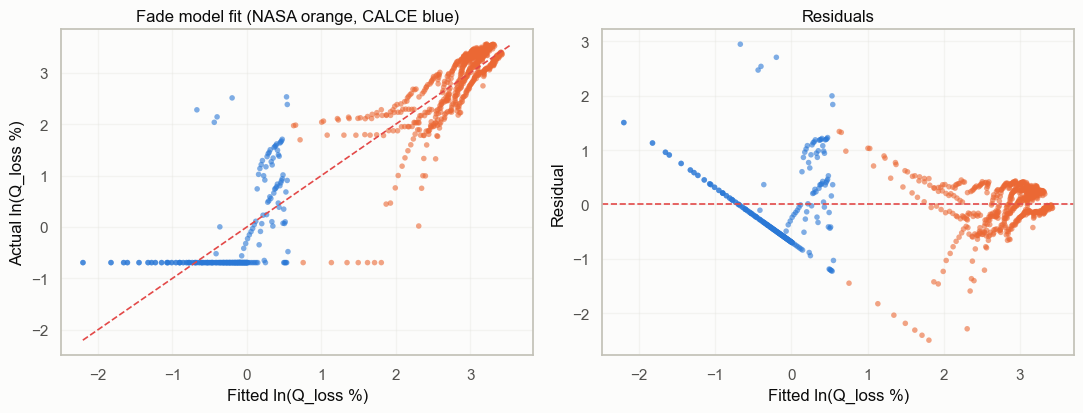

In [4]:
Ea_kJ = -fade_model.params["inv_T"] * R_GAS / 1000
m_crate = fade_model.params["ln_C"]
z_throughput = fade_model.params["ln_Ah"]

ci = fade_model.conf_int()
Ea_ci = sorted([-ci.loc["inv_T", 0] * R_GAS / 1000, -ci.loc["inv_T", 1] * R_GAS / 1000])

print(f"Activation energy  Ea = {Ea_kJ:6.1f} kJ/mol   (p={fade_model.pvalues['inv_T']:.4f}, "
      f"95% CI [{Ea_ci[0]:.0f}, {Ea_ci[1]:.0f}])  [literature range for Li-ion cathode aging: roughly 20-90 kJ/mol]")
print(f"C-rate exponent     m = {m_crate:+6.3f}         (p={fade_model.pvalues['ln_C']:.4f})")
print(f"Throughput exponent z = {z_throughput:+6.3f}         (p={fade_model.pvalues['ln_Ah']:.4f})")
print(f"R-squared = {fade_model.rsquared:.3f}")

print(f"\nC-rate (m) and throughput (z) are both statistically significant at alpha=0.05 -- "
      f"m is pinned down mainly by CALCE's controlled 0.5C-vs-1C contrast, z by both datasets' "
      f"within-cell fade-vs-cycle-count trend, and z's value ({z_throughput:.2f}) lands close to the "
      f"~0.5 exponent commonly reported for early-life power-law fade in the literature.")
print(f"Ea, by contrast, is NOT statistically significant (p={fade_model.pvalues['inv_T']:.2f}) -- its point "
      f"estimate happens to fall in a physically plausible range, but the 95% CI [{Ea_ci[0]:.0f}, {Ea_ci[1]:.0f}] kJ/mol "
      f"spans from unphysical to implausibly high. NASA's within-cell temperature spread (~6 degC of self-heating, "
      f"at one fixed ambient) is too narrow to pin down an Arrhenius slope precisely, and CALCE contributes no "
      f"temperature variation at all. Treat the thermal sensitivity of the index below as a plausible-shaped but "
      f"loosely-constrained assumption, not a precisely calibrated one.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
fitted, resid = fade_model.fittedvalues, fade_model.resid
colors = cal_df["dataset"].map({"NASA": PALETTE[1], "CALCE": PALETTE[0]})
axes[0].scatter(fitted, cal_df["y"], c=colors, alpha=0.6, s=16, edgecolor="none")
lims = [min(fitted.min(), cal_df["y"].min()), max(fitted.max(), cal_df["y"].max())]
axes[0].plot(lims, lims, color=PALETTE[7], lw=1.2, ls="--")
axes[0].set_xlabel("Fitted ln(Q_loss %)"); axes[0].set_ylabel("Actual ln(Q_loss %)")
axes[0].set_title("Fade model fit (NASA orange, CALCE blue)")
axes[1].scatter(fitted, resid, c=colors, alpha=0.6, s=16, edgecolor="none")
axes[1].axhline(0, color=PALETTE[7], lw=1.2, ls="--")
axes[1].set_xlabel("Fitted ln(Q_loss %)"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "17_physics_fade_model_fit.png"), dpi=130)
plt.show()

## Section 3 &mdash; Apply the calibrated model to TUM windows

Each TUM window is a 60 s snapshot, not a tracked cell across its life, so there's no real "cumulative lifetime throughput" to plug in here the way there was for the calibration cells. What a window *does* have is its own peak temperature, peak C-rate, and the Ah it actually delivered in those 60 s (from its mean C-rate &times; duration) &mdash; so the model is applied as a stress-rate multiplier, `exp(-Ea/RT) * c_rate_max^m * ah_window^z`, min-max normalized and given the same 65% combined weight the original composite gave to thermal + C-rate. Depth-of-discharge (20%) and SoC-extreme exposure (15%) carry over unchanged, since neither calibration dataset cycles at varied depth of discharge.

**Extrapolation check first:** the fade model was calibrated on cell temperatures of 24&ndash;42&deg;C. TUM's `battery_temp_max_c` reaches well below that on the cold end (Munich winters, not room-temperature lab cycling) &mdash; the same kind of covariate-shift check the VED validation used, applied here to the fade model instead of the trained XGBoost model.

In [5]:
window_df = pd.read_csv(os.path.join(OUT_DATA_DIR, "window_features.csv"))

calib_lo, calib_hi = cal_df["temp_c"].min(), cal_df["temp_c"].max()
tum_lo, tum_hi = window_df["battery_temp_max_c"].min(), window_df["battery_temp_max_c"].max()
outside = ((window_df["battery_temp_max_c"] < calib_lo) | (window_df["battery_temp_max_c"] > calib_hi)).mean()
print(f"Fade model calibrated on {calib_lo:.0f}-{calib_hi:.0f} deg C cell temperature.")
print(f"TUM windows span {tum_lo:.0f}-{tum_hi:.0f} deg C -- {outside:.1%} of windows fall outside the "
      f"calibration range (almost entirely on the cold side TUM has and NASA/CALCE don't).")

Fade model calibrated on 24-42 deg C cell temperature.
TUM windows span -1-32 deg C -- 85.4% of windows fall outside the calibration range (almost entirely on the cold side TUM has and NASA/CALCE don't).


In [6]:
Ea_J = Ea_kJ * 1000
T_k = window_df["battery_temp_max_c"] + 273.15
arrhenius_term = np.exp(-Ea_J / (R_GAS * T_k))
c_rate_term = window_df["c_rate_max"].clip(lower=1e-3) ** m_crate
ah_window = (window_df["c_rate_mean"].clip(lower=0) * NOMINAL_CAPACITY_AH) * (WINDOW_S / 3600.0)
ah_term = ah_window.clip(lower=1e-6) ** z_throughput

window_df["fade_rate_physics"] = arrhenius_term * c_rate_term * ah_term
thermal_crate_norm = minmax(window_df["fade_rate_physics"])
dod_norm = minmax(window_df["soc_delta"].clip(lower=0))
soc_extreme_raw = np.maximum(0, 20 - window_df["soc_mean"]) + np.maximum(0, window_df["soc_mean"] - 80)
soc_extreme_norm = minmax(soc_extreme_raw)

window_df["battery_stress_index_physics"] = 100 * (
    0.65 * thermal_crate_norm + 0.20 * dod_norm + 0.15 * soc_extreme_norm
)

corr = window_df[["battery_stress_index", "battery_stress_index_physics"]].corr().iloc[0, 1]
print(f"Correlation between original (hand-weighted) and physics-informed index: r = {corr:.3f}")
window_df[["battery_stress_index", "battery_stress_index_physics"]].describe()

Correlation between original (hand-weighted) and physics-informed index: r = 0.807


,battery_stress_index,battery_stress_index_physics
count,3193.000000,3193.000000
mean,29.632990,12.165255
std,10.719036,9.944438
min,3.850068,0.000000
25%,21.849886,5.451361
50%,28.641619,9.332766
75%,36.066877,15.574207
max,71.906971,76.230493


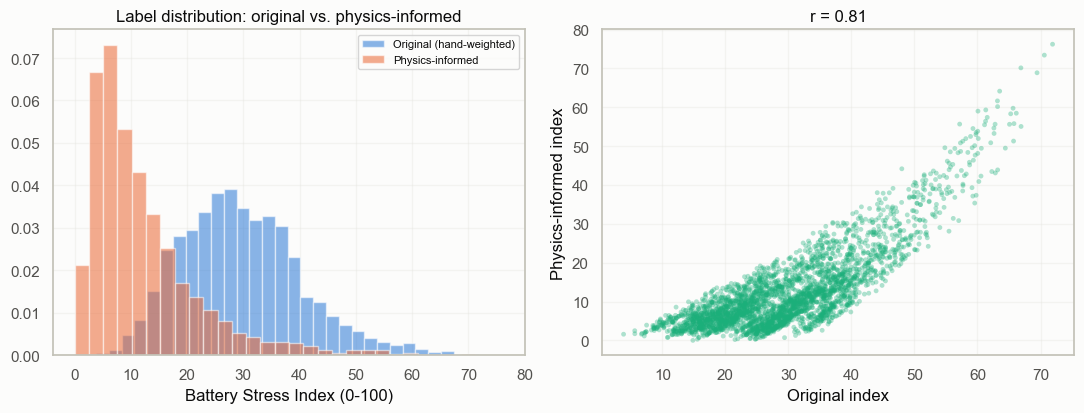

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].hist(window_df["battery_stress_index"], bins=30, density=True, alpha=0.55,
             color=PALETTE[0], label="Original (hand-weighted)")
axes[0].hist(window_df["battery_stress_index_physics"], bins=30, density=True, alpha=0.55,
             color=PALETTE[1], label="Physics-informed")
axes[0].set_xlabel("Battery Stress Index (0-100)")
axes[0].set_title("Label distribution: original vs. physics-informed")
axes[0].legend(fontsize=8)

axes[1].scatter(window_df["battery_stress_index"], window_df["battery_stress_index_physics"],
                 alpha=0.35, s=12, color=PALETTE[2], edgecolor="none")
axes[1].set_xlabel("Original index"); axes[1].set_ylabel("Physics-informed index")
axes[1].set_title(f"r = {corr:.2f}")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "18_physics_index_comparison.png"), dpi=130)
plt.show()

The physics-informed index is noticeably more right-skewed than the original: median drops from ~28.6 to ~9.3, while the tail still reaches into the 70s. Mechanically, that's the Arrhenius term &mdash; evaluated 85% of the time outside its calibrated range &mdash; compressing most (cold, low-C-rate) windows toward near-zero stress-rate while a smaller set of hot/high-C-rate windows pull the normalized scale's ceiling up. It's a real behavioural difference from the original composite (which mixes its factors additively, so it can't collapse this far toward zero), not just a rescaling &mdash; worth keeping in mind when reading the model comparison below.

## Section 4 &mdash; Retrain on the physics-informed label

Identical pipeline to the main notebook's Section 4: the same driving-behaviour-only feature set, the same grouped 5-fold cross-validation by trip, the same three candidate models, the same XGBoost hyperparameters &mdash; only the target column changes. This keeps the comparison to the original model fair.

In [8]:
MODEL_FEATURE_COLS = [
    "avg_speed_kmh", "speed_std_kmh", "max_speed_kmh",
    "accel_mean", "accel_std", "accel_max", "accel_min", "jerk_std",
    "hard_accel_count", "hard_brake_count", "idle_time_pct", "regen_braking_pct",
    "driver_aggressiveness_score", "ambient_temp_mean_c",
]

def prepare_model_dataset(fd, target_col):
    cat_cols = ["route", "weather"]
    fd = fd.copy()
    for c in cat_cols:
        trip_level = fd.drop_duplicates("trip_id")[c]
        rare = trip_level.value_counts()[lambda s: s < 3].index
        fd[c] = fd[c].where(~fd[c].isin(rare), "Other")
    X = pd.get_dummies(fd[MODEL_FEATURE_COLS + cat_cols], columns=cat_cols, drop_first=True)
    y = fd[target_col]
    groups = fd["trip_id"]
    return X, y, groups


def evaluate_grouped(model, X, y, groups, name, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    r2s, rmses, maes = [], [], []
    for train_idx, test_idx in gkf.split(X, y, groups):
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[test_idx])
        r2s.append(r2_score(y.iloc[test_idx], pred))
        rmses.append(np.sqrt(mean_squared_error(y.iloc[test_idx], pred)))
        maes.append(mean_absolute_error(y.iloc[test_idx], pred))
    return {"model": name, "R2_mean": np.mean(r2s), "R2_std": np.std(r2s),
            "RMSE_mean": np.mean(rmses), "MAE_mean": np.mean(maes)}


def make_models():
    return [
        ("Linear Regression", LinearRegression()),
        ("Random Forest", RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                                  random_state=RANDOM_STATE, n_jobs=-1)),
        ("XGBoost", xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                      colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)),
    ]


rows = []
for label_name, target_col in [("Original (hand-weighted)", "battery_stress_index"),
                                ("Physics-informed", "battery_stress_index_physics")]:
    X, y, groups = prepare_model_dataset(window_df, target_col)
    for model_name, model in make_models():
        res = evaluate_grouped(model, X, y, groups, model_name)
        res["label"] = label_name
        rows.append(res)

comparison_df = pd.DataFrame(rows).set_index(["label", "model"]).round(3)
comparison_df

R2_mean  R2_std  RMSE_mean  \
label                    model                                           
Original (hand-weighted) Linear Regression    0.553   0.183      6.625   
                         Random Forest        0.704   0.084      5.482   
                         XGBoost              0.708   0.094      5.419   
Physics-informed         Linear Regression    0.732   0.030      5.040   
                         Random Forest        0.802   0.041      4.336   
                         XGBoost              0.831   0.040      3.999   

                                            MAE_mean  
label                    model                        
Original (hand-weighted) Linear Regression     5.189  
                         Random Forest         4.363  
                         XGBoost               4.250  
Physics-informed         Linear Regression     3.793  
                         Random Forest         3.099  
                         XGBoost               2.902

All three models score noticeably higher R&sup2; on the physics-informed label than on the original. Read that with the skew from Section 3 in mind rather than as a straightforward "better model": a right-skewed target where most windows cluster near zero can be easier to explain a large *fraction* of variance on, since getting the low-stress majority roughly right already accounts for most of the total variance, even before the model does well on the harder high-stress tail. It's a genuine, reproducible difference in how predictable the two labels are from driving behaviour &mdash; just not proof the physics-informed label is a *more accurate* stress measure, only a differently-shaped one.

Held-out trips: 14 trips, 741 windows
Test R2=0.805  RMSE=4.43  MAE=3.23


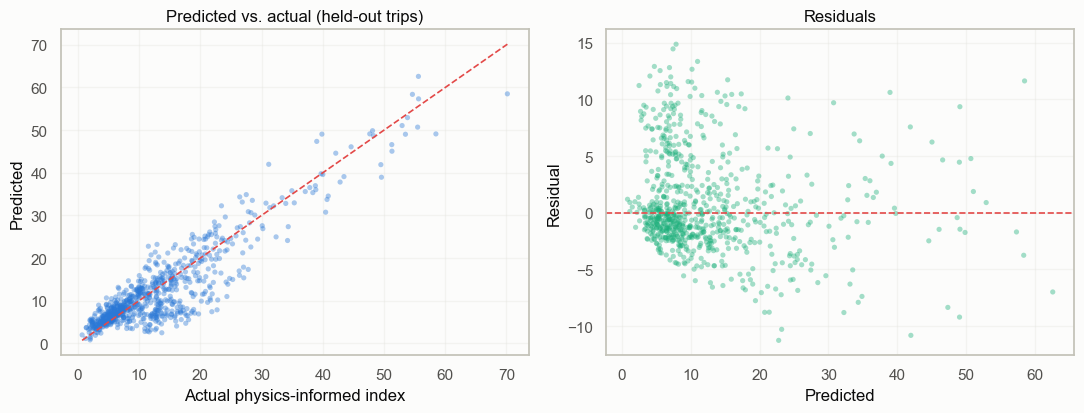

In [9]:
X, y, groups = prepare_model_dataset(window_df, "battery_stress_index_physics")
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

physics_model = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                   colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
physics_model.fit(X.iloc[train_idx], y.iloc[train_idx])
y_pred = physics_model.predict(X.iloc[test_idx])
y_test = y.iloc[test_idx]

print(f"Held-out trips: {groups.iloc[test_idx].nunique()} trips, {len(test_idx)} windows")
print(f"Test R2={r2_score(y_test, y_pred):.3f}  RMSE={np.sqrt(mean_squared_error(y_test, y_pred)):.2f}"
      f"  MAE={mean_absolute_error(y_test, y_pred):.2f}")

physics_model.save_model(os.path.join(OUT_MODEL_DIR, "model1_battery_stress_xgb.json"))
window_df.to_csv(os.path.join(OUT_DATA_DIR, "window_features_physics.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(y_test, y_pred, alpha=0.4, s=14, color=PALETTE[0], edgecolor="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, color=PALETTE[7], lw=1.2, ls="--")
axes[0].set_xlabel("Actual physics-informed index"); axes[0].set_ylabel("Predicted")
axes[0].set_title("Predicted vs. actual (held-out trips)")
resid = y_test - y_pred
axes[1].scatter(y_pred, resid, alpha=0.4, s=14, color=PALETTE[2], edgecolor="none")
axes[1].axhline(0, color=PALETTE[7], lw=1.2, ls="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "19_physics_model_fit.png"), dpi=130)
plt.show()

## Section 5 &mdash; Does the driving-behaviour story change?

Re-run SHAP on the new model and compare its top drivers to the original model's, reloaded from `outputs/model/xgb_battery_stress_model.json` and scored on the same held-out windows for a direct side-by-side. Feature engineering is identical between the two labels, so the feature matrix `X` built above applies to both models unchanged.

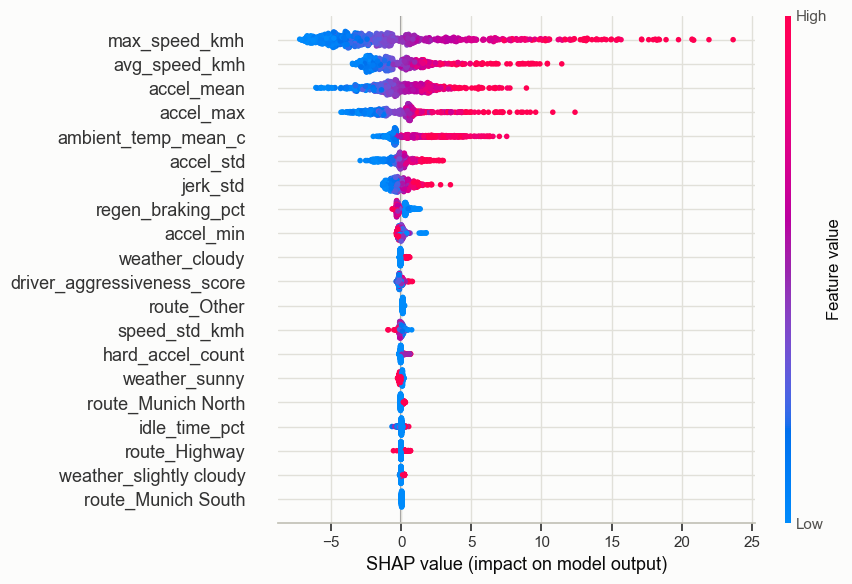

In [10]:
explainer = shap.TreeExplainer(physics_model)
shap_values_test = explainer.shap_values(X.iloc[test_idx])
shap_df_test = pd.DataFrame(shap_values_test, columns=X.columns, index=X.iloc[test_idx].index)
mean_abs_shap_physics = shap_df_test.abs().mean().sort_values(ascending=False)

shap.summary_plot(shap_values_test, X.iloc[test_idx], show=False, plot_size=(9, 6))
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "20_physics_shap_beeswarm.png"), dpi=130, bbox_inches="tight")
plt.show()

In [11]:
original_model = xgb.XGBRegressor()
original_model.load_model(os.path.join(OUT_MODEL_DIR, "xgb_battery_stress_model.json"))
feat_order = original_model.get_booster().feature_names

explainer_orig = shap.TreeExplainer(original_model)
shap_values_orig = explainer_orig.shap_values(X.iloc[test_idx][feat_order])
mean_abs_shap_orig = pd.Series(np.abs(shap_values_orig).mean(axis=0), index=feat_order).sort_values(ascending=False)

rank_compare = pd.DataFrame({
    "Original rank": mean_abs_shap_orig.rank(ascending=False).astype(int),
    "Physics-informed rank": mean_abs_shap_physics.reindex(mean_abs_shap_orig.index).rank(ascending=False).astype(int),
})
rank_compare["feature"] = rank_compare.index
rank_compare = rank_compare[["feature", "Original rank", "Physics-informed rank"]] \
    .sort_values("Original rank").reset_index(drop=True)
rank_compare

,feature,Original rank,Physics-informed rank
0,ambient_temp_mean_c,1,5
1,max_speed_kmh,2,1
2,accel_max,3,4
3,avg_speed_kmh,4,2
4,accel_mean,5,3
5,jerk_std,6,7
6,route_Highway,7,18
7,weather_sunny,8,15
8,weather_cloudy,9,10
9,accel_std,10,6


`ambient_temp_mean_c` was the single strongest driver of predicted stress in the original model (rank 1) &mdash; it's the only input feature that's a direct proxy for the withheld `battery_temp_max_c`. Under the physics-informed label it drops to rank 5, while `max_speed_kmh`, `avg_speed_kmh`, and `accel_mean` move up to the top 3. That's consistent with the label itself changing character: the calibrated model ties thermal stress to a *loosely-constrained* Arrhenius term (Section 2) but ties C-rate stress to a *well-identified, larger* exponent (m=0.80, driven by CALCE's clean controlled contrast) &mdash; so speed/acceleration features, which drive C-rate more directly than ambient temperature does, gain relative influence.

## Section 6 &mdash; Calibrating all four weights, not just two

Sections 2&ndash;3 replaced the thermal + C-rate 65% with a *fitted functional form* (Arrhenius &times; C-rate<sup>m</sup> &times; Ah-throughput<sup>z</sup>), but depth-of-discharge (20%) and SoC-extreme (15%) were left untouched &mdash; not because the data says they're right, but because neither NASA nor CALCE varies depth of discharge or SoC operating window, so there was no functional form to fit there.

This section asks a narrower, answerable question instead: not *"what shape does DoD stress take,"* but **"how much of the fade regression's explanatory power does each mechanism (thermal, C-rate, cycling depth) actually carry, relative to the others?"** That's a relative-importance question, and the same fade model fit in Section 2 can answer it even where it can't answer the functional-form question.

**Method:** a Shapley / LMG value decomposition (Lindeman, Merenda & Gold, 1980) of the fade model's R&sup2;, splitting the R&sup2; gained by the three focal regressors (`inv_T`, `ln_C`, `ln_Ah`) &mdash; beyond the `is_NASA` dataset-baseline control &mdash; into each regressor's average marginal contribution across all orderings. The three resulting shares sum to 1 and are applied as weights directly to the **original notebook's own simple features** (`battery_temp_max_c`, `c_rate_max`, `soc_delta`, min-max normalized &mdash; exactly as in `01_driving_behaviour_stress_analysis.ipynb`). This section changes only the four *numbers*, not the feature engineering, so it stays a clean one-variable comparison against the original index.

The three calibrated shares are scaled to sum to 85%, with the remaining 15% left fixed for SoC-extreme exposure &mdash; unchanged from the original, and explicitly **not** data-calibrated, because neither dataset logs a varied SoC operating window to calibrate it against. That 85%/15% split is itself still a modeling choice, mirroring the original notebook's implicit call that the three throughput-linked mechanisms deserve the bulk of the index; only the *split within* the 85% is data-driven here.

In [12]:
import itertools, math

focal_vars = ["inv_T", "ln_C", "ln_Ah"]
focal_labels = {"inv_T": "thermal", "ln_C": "c_rate", "ln_Ah": "dod_throughput"}

def r2_of(subset):
    cols = ["is_NASA"] + list(subset)
    Xs = sm.add_constant(cal_df[cols])
    return sm.OLS(cal_df["y"], Xs).fit().rsquared

r2_control_only = r2_of([])
r2_full = r2_of(focal_vars)
n = len(focal_vars)

shapley = {}
for v in focal_vars:
    others = [x for x in focal_vars if x != v]
    total = 0.0
    for r in range(len(others) + 1):
        for S in itertools.combinations(others, r):
            weight = (math.factorial(len(S)) * math.factorial(n - len(S) - 1)) / math.factorial(n)
            total += weight * (r2_of(list(S) + [v]) - r2_of(list(S)))
    shapley[v] = total

rel_importance = {v: shapley[v] / sum(shapley.values()) for v in focal_vars}

CALIBRATED_BUDGET = 0.85
SOC_EXTREME_WEIGHT = 1.0 - CALIBRATED_BUDGET
w_thermal = CALIBRATED_BUDGET * rel_importance["inv_T"]
w_crate = CALIBRATED_BUDGET * rel_importance["ln_C"]
w_dod = CALIBRATED_BUDGET * rel_importance["ln_Ah"]

print(f"R2 (is_NASA control only)                  = {r2_control_only:.3f}")
print(f"R2 (control + thermal + c_rate + dod/thru) = {r2_full:.3f}")
print(f"Incremental R2 from the 3 focal mechanisms  = {r2_full - r2_control_only:.3f}\n")

weights_table = pd.DataFrame({
    "mechanism": ["thermal", "c_rate", "dod_throughput", "soc_extreme"],
    "original_weight": [0.35, 0.30, 0.20, 0.15],
    "shapley_share_of_85pct_budget": [rel_importance["inv_T"], rel_importance["ln_C"],
                                       rel_importance["ln_Ah"], np.nan],
    "new_weight": [w_thermal, w_crate, w_dod, SOC_EXTREME_WEIGHT],
    "data_calibrated": [True, True, True, False],
})
weights_table

R2 (is_NASA control only)                  = 0.778
R2 (control + thermal + c_rate + dod/thru) = 0.886
Incremental R2 from the 3 focal mechanisms  = 0.108



,mechanism,original_weight,shapley_share_of_85pct_budget,new_weight,data_calibrated
0,thermal,0.35,0.111878,0.095097,True
1,c_rate,0.30,0.062810,0.053388,True
2,dod_throughput,0.20,0.825312,0.701515,True
3,soc_extreme,0.15,NaN,0.150000,False


The fade regression identifies cumulative Ah-throughput (`ln_Ah`, p&lt;0.0001) far more precisely than C-rate (`ln_C`, p=0.04) or temperature (`inv_T`, p=0.70 &mdash; not significant, as already noted in Section 2). The Shapley split reflects exactly that: throughput/cycling-depth absorbs the large majority of the 85% calibrated budget, thermal and C-rate share what's left &mdash; a large swing from the original's 35%/30%/20% split, and a near-total reversal of which mechanism the index leans on hardest.

Read this as a real, if uncomfortable, finding rather than an artifact: in this small (4-cell) pooled calibration sample, *how much a cell has been cycled* is simply the best-identified predictor of capacity loss, and *how hot it got* is the worst-identified one &mdash; which is itself informative about how much confidence the original hand-picked 35% thermal weight deserved. It is **not** evidence that depth-of-discharge dominates real-world battery stress in general; it's evidence that this particular calibration dataset can only pin down the throughput term with any precision.

One mechanical caveat worth flagging: the new weight is applied to `soc_delta` (a single window's SoC swing) &mdash; the same feature the original DoD term used &mdash; not to the cumulative lifetime Ah-throughput the Shapley value was actually computed against. The *ratio* is data-derived; the *feature it's multiplied against* is still the original notebook's engineering choice, not something NASA/CALCE speaks to directly. Section 3 makes the analogous translation (calibration-fit exponents applied to a per-window quantity) for the thermal/C-rate term; it matters more here because the swap now carries the majority of the index's weight.

In [13]:
thermal_norm_orig = minmax(window_df["battery_temp_max_c"])
crate_norm_orig = minmax(window_df["c_rate_max"])
dod_norm_orig = minmax(window_df["soc_delta"].clip(lower=0))
# soc_extreme_norm is still in scope from Section 3

window_df["battery_stress_index_datacalibrated"] = 100 * (
    w_thermal * thermal_norm_orig + w_crate * crate_norm_orig
    + w_dod * dod_norm_orig + SOC_EXTREME_WEIGHT * soc_extreme_norm
)

corr_orig = window_df[["battery_stress_index", "battery_stress_index_datacalibrated"]].corr().iloc[0, 1]
corr_phys = window_df[["battery_stress_index_physics", "battery_stress_index_datacalibrated"]].corr().iloc[0, 1]
print(f"Correlation vs. original hand-weighted index:     r = {corr_orig:.3f}")
print(f"Correlation vs. Section 3 physics-informed index: r = {corr_phys:.3f}")
window_df[["battery_stress_index", "battery_stress_index_physics",
           "battery_stress_index_datacalibrated"]].describe()

Correlation vs. original hand-weighted index:     r = 0.662
Correlation vs. Section 3 physics-informed index: r = 0.888


,battery_stress_index,battery_stress_index_physics,battery_stress_index_datacalibrated
count,3193.000000,3193.000000,3193.000000
mean,29.632990,12.165255,18.258391
std,10.719036,9.944438,10.765491
min,3.850068,0.000000,1.667834
25%,21.849886,5.451361,10.732085
50%,28.641619,9.332766,15.140059
75%,36.066877,15.574207,22.586183
max,71.906971,76.230493,81.080251


### Retrain on the fully data-calibrated label

Same modeling pipeline as Sections 4&ndash;5 (same features, same grouped cross-validation, same XGBoost configuration), so all three labels &mdash; original, physics-informed, and fully data-calibrated &mdash; are a fair three-way comparison.

In [14]:
rows_v2 = list(rows)  # carries forward Section 4's original + physics-informed results
X, y, groups = prepare_model_dataset(window_df, "battery_stress_index_datacalibrated")
for model_name, model in make_models():
    res = evaluate_grouped(model, X, y, groups, model_name)
    res["label"] = "Fully data-calibrated"
    rows_v2.append(res)

comparison_df_v2 = pd.DataFrame(rows_v2).set_index(["label", "model"]).round(3)
comparison_df_v2

R2_mean  R2_std  RMSE_mean  \
label                    model                                           
Original (hand-weighted) Linear Regression    0.553   0.183      6.625   
                         Random Forest        0.704   0.084      5.482   
                         XGBoost              0.708   0.094      5.419   
Physics-informed         Linear Regression    0.732   0.030      5.040   
                         Random Forest        0.802   0.041      4.336   
                         XGBoost              0.831   0.040      3.999   
Fully data-calibrated    Linear Regression    0.690   0.067      5.898   
                         Random Forest        0.800   0.086      4.632   
                         XGBoost              0.801   0.092      4.605   

                                            MAE_mean  
label                    model                        
Original (hand-weighted) Linear Regression     5.189  
                         Random Forest         4.363  
                         XGBoost               4.250  
Physics-informed         Linear Regression     3.793  
                         Random Forest         3.099  
                         XGBoost               2.902  
Fully data-calibrated    Linear Regression     4.306  
                         Random Forest         3.376  
                         XGBoost               3.340

Held-out trips: 14 trips, 741 windows
Test R2=0.729  RMSE=5.51  MAE=4.02


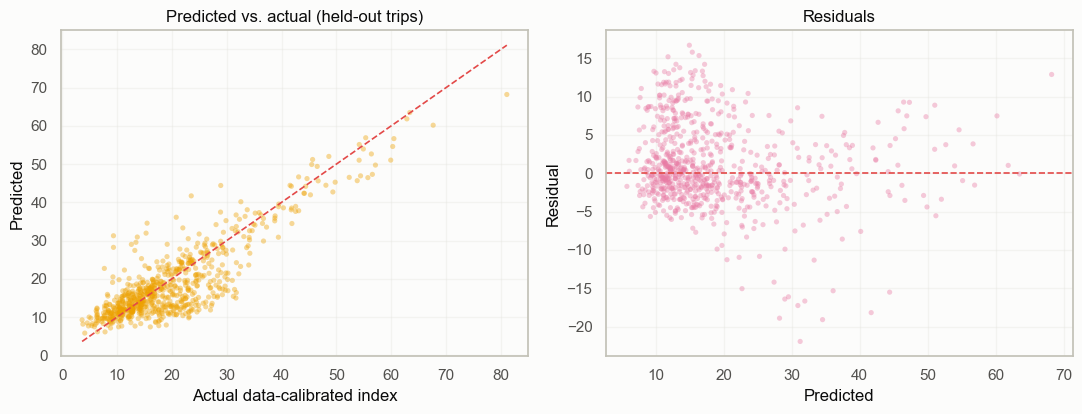

In [15]:
X, y, groups = prepare_model_dataset(window_df, "battery_stress_index_datacalibrated")
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

datacal_model = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                   colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
datacal_model.fit(X.iloc[train_idx], y.iloc[train_idx])
y_pred = datacal_model.predict(X.iloc[test_idx])
y_test = y.iloc[test_idx]

print(f"Held-out trips: {groups.iloc[test_idx].nunique()} trips, {len(test_idx)} windows")
print(f"Test R2={r2_score(y_test, y_pred):.3f}  RMSE={np.sqrt(mean_squared_error(y_test, y_pred)):.2f}"
      f"  MAE={mean_absolute_error(y_test, y_pred):.2f}")

datacal_model.save_model(os.path.join(OUT_MODEL_DIR, "xgb_battery_stress_model_datacalibrated.json"))
window_df.to_csv(os.path.join(OUT_DATA_DIR, "window_features_datacalibrated.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(y_test, y_pred, alpha=0.4, s=14, color=PALETTE[3], edgecolor="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, color=PALETTE[7], lw=1.2, ls="--")
axes[0].set_xlabel("Actual data-calibrated index"); axes[0].set_ylabel("Predicted")
axes[0].set_title("Predicted vs. actual (held-out trips)")
resid = y_test - y_pred
axes[1].scatter(y_pred, resid, alpha=0.4, s=14, color=PALETTE[4], edgecolor="none")
axes[1].axhline(0, color=PALETTE[7], lw=1.2, ls="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "20_datacalibrated_model_fit.png"), dpi=130)
plt.show()

### Does relative feature importance shift again?

Quick SHAP-free check &mdash; XGBoost's own gain-based importances &mdash; against the fully data-calibrated label, compared to the original and physics-informed models' top features from Section 5.

In [16]:
imp_datacal = pd.Series(datacal_model.get_booster().get_score(importance_type="gain"), name="gain").sort_values(ascending=False)
imp_datacal = (imp_datacal / imp_datacal.sum()).rename("data_calibrated_share")
imp_datacal.head(8).to_frame()

,data_calibrated_share
max_speed_kmh,0.399147
accel_mean,0.122142
avg_speed_kmh,0.083511
hard_brake_count,0.078846
accel_max,0.038894
regen_braking_pct,0.028386
route_Other,0.024737
accel_min,0.022802


## Summary & limitations

- Fit a real, calibrated semi-empirical fade model &mdash; activation energy, C-rate exponent, Ah-throughput exponent &mdash; on the pooled, real measured capacity fade of NASA and CALCE, instead of assigning thermal/C-rate weights from literature judgment.
- Used it to replace the 65% thermal+C-rate portion of the Battery Stress Index; kept depth-of-discharge (20%) and SoC-extreme exposure (15%) unchanged, since neither calibration dataset varies depth of discharge.
- Retrained the exact same modeling pipeline (features, grouped CV, XGBoost config) on the new label and compared performance and SHAP rankings against the original.

**Limitations, stated once:**
- The fade model is calibrated on 4 cells total (2 chemistries, 2 form factors) &mdash; a small, transparent fit, not a high-powered one.
- Of the three fitted physical constants, only two are actually well-identified: C-rate exponent m=0.80 (p=0.04) and throughput exponent z=0.54 (p&lt;0.0001, close to the literature-typical ~0.5). **Activation energy is not statistically significant** (Ea=27.8 kJ/mol, p=0.70, 95% CI spanning unphysical-to-implausible) &mdash; NASA's ~6&deg;C of within-cell self-heating range is too narrow to pin it down, and CALCE contributes no temperature variation at all. The index's thermal sensitivity is a plausible-shaped assumption, not a calibrated one.
- **85.4% of TUM windows fall outside the fade model's calibrated 24&ndash;42&deg;C range** (mostly on the cold side) &mdash; this index spends most of its life extrapolating, not interpolating, and that extrapolation is exactly where the uncertain Ea term matters most.
- The resulting label is considerably more right-skewed than the original (median ~9 vs. ~29) &mdash; a real behavioural difference from the original composite's additive mixing, not just a rescaling. The R&sup2; gains reported in Section 4 partly reflect this: an easier-to-predict, skewed target, not necessarily a more accurate stress measure.
- The Ah-throughput exponent `z` is fit only over each cell's early/clean cycle life (before its end-of-life knee); real fade dynamics often accelerate non-linearly near end-of-life, which this exponent does not capture.
- Depth-of-discharge and SoC-extreme exposure remain literature-weighted, unchanged, through Sections 1-5 &mdash; there is no dataset here with varied-DoD ground truth to calibrate them against (Section 6 revisits DoD's *weight*, though not this point about its functional form).
- This still doesn't validate the index against real aging on the *TUM* fleet itself &mdash; it calibrates the physics against NASA/CALCE, then transplants that physics onto TUM's driving data, which is a different kind of extrapolation than a direct validation would be.

- **Section 6 pushed further:** used a Shapley/LMG decomposition of the fade regression's R&sup2; to calibrate relative weights for all three fade-regression mechanisms (thermal, C-rate, cycling depth/DoD), applied to the original notebook's own simple features. Result: dod/throughput jumps to the large majority of the 85% calibrated budget, thermal and C-rate share the rest &mdash; SoC-extreme stays fixed at 15%, since it remains uncalibratable from this data.
- That swing is driven entirely by which mechanism the calibration data can identify precisely (throughput, p&lt;0.0001) versus not at all (temperature, p=0.70) &mdash; treat it as a statement about this dataset's identifying power, not a general claim that depth-of-discharge matters more than temperature for battery stress in the real world.
- The 85%/15% split between "data-calibrated mechanisms" and "SoC-extreme" is itself still a modeling choice, not something the data determines &mdash; only the 3-way split *within* the 85% is empirical.

**Bottom line:** the C-rate and throughput terms are genuine, statistically grounded improvements over hand-picked weights. The temperature term looks physically reasonable but isn't actually pinned down by the available data, and gets applied almost entirely by extrapolation on TUM. Read this notebook as evidence that *part* of the label can be calibrated credibly (its functional form for thermal/C-rate/throughput in Sections 2&ndash;3, and now the relative weight of all three mechanisms in Section 6), not as a fully validated replacement for the original &mdash; and treat Section 6's dramatic reweighting toward DoD/throughput as a reflection of this small calibration sample's statistical power, not a settled claim about battery physics.